# Mudanças de especificação inacabadas no OpenSpec
## 01 — Compreensão do negócio e dos dados

Primeira etapa do processo KDD: objetivos, dados, sanidade e exploração das mudanças OpenSpec.
Todos os números são calculados neste notebook a partir do SpecMine v1.0; nada é simulado ou imputado.

**Convenção:** **[Fato]** = observado nos dados · **[Interpretação]** = nossa leitura · **[Hipótese]** = a testar.

## 1. Objetivos

**Pergunta de pesquisa.** Com que frequência mudanças de especificação OpenSpec ficam inacabadas, e o que as distingue das concluídas?

**Contexto.** No OpenSpec, cada mudança vive em `openspec/changes/<nome>/`, com `proposal.md`, `tasks.md` (uma lista de checkboxes),
opcionalmente `design.md`, e *spec deltas* em `specs/**/spec.md`. Ao terminar, a pasta é movida para
`openspec/changes/archive/AAAA-MM-DD-<nome>/` e os deltas são aplicados às specs vivas em `openspec/specs/`.
O processo registra o próprio fim, o que torna "inacabado" observável.

**Objetivos de negócio.**

- *Primário:* estimar com que frequência mudanças OpenSpec ficam inacabadas (nunca arquivadas, ou arquivadas com tarefas pendentes) e caracterizar o que as distingue das concluídas.
- *Secundário:* identificar em que ponto do fluxo (proposta → tarefas → arquivamento) as mudanças param e que tipo de trabalho fica para trás.

**Objetivos de mineração.**

| Objetivo | Tarefa | Técnica candidata |
|---|---|---|
| OM1. Classificar cada mudança em um estado do ciclo de vida e estimar a frequência de cada estado | Caracterização e estimativa | Regras operacionais de estado; sensibilidade a limiares |
| OM2. Descobrir combinações de atributos associadas a mudanças inacabadas | Regras de associação | Apriori / FP-Growth com consequente no estado |
| OM3. Descobrir perfis de mudanças sem rótulo prévio | Agrupamento | k-means ou hierárquico, *k* por silhueta |

**Unidade de análise:** a mudança (pasta `changes/<nome>/` ativa ou `changes/archive/<data>-<nome>/` arquivada).

**Estados (definição operacional, OM1):**

| Estado | Condição | Conta como inacabada? |
|---|---|---|
| Concluída | arquivada, todas as tarefas marcadas | não |
| Concluída com pendências | arquivada, ao menos uma tarefa desmarcada | sim (potencial) |
| Em andamento | ativa, último commit há menos de *T* dias | não (censurada) |
| Ultrapassada | ativa, parada há ≥ *T* dias, e o repositório arquivou outra mudança depois | sim (potencial) |
| Parada | ativa, parada há ≥ *T* dias, e o repositório não arquivou nada depois | sim (potencial) |

Este notebook cobre a compreensão dos dados e um protótipo de OM1 na amostra. OM1 no censo completo, OM2 e OM3 ficam para os próximos notebooks.

## 2. Configuração

Requer o clone da amostra oficial do SpecMine (commit `da606c8`) ao lado deste repositório, ou a variável `SPECMINE_SAMPLE`
(ver `README.md`). A Seção 7 usa colunas do censo completo baixadas por `scripts/download_data.py`.

In [1]:
from pathlib import Path
import json, os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
import sys

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
SAMPLE_DIR = Path(os.environ.get('SPECMINE_SAMPLE', ROOT.parent / 'specmine-official'))
DATA_DIR = SAMPLE_DIR / 'data'
assert DATA_DIR.exists(), f'Amostra do SpecMine não encontrada em {DATA_DIR} (ver README)'
CACHE = ROOT / 'data_cache'
OUT = ROOT / 'outputs' / '01_data_understanding'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for p in (FIG, TAB): p.mkdir(parents=True, exist_ok=True)

SEED = 20260711
OBS_END = pd.Timestamp('2026-07-11 23:59:59', tz='UTC')   # fim do crawl de commits do SpecMine
THRESHOLDS = [30, 60, 90]                                  # limiares de "parada" (dias)
sys.path.insert(0, str(ROOT / 'src'))
from openspec_changes import (RX_CHANGE, RX_ARCHIVE_DATE, PENDING_CATEGORIES, UNCATEGORIZED,
                              build_change_table, pending_items)
R = {}                                                     # números-chave exportados

C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100', gray='#8c8b86',
         light='#d9d8d2', ink='#0b0b0b', ink2='#52514e')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.edgecolor': C['gray'], 'xtick.color': C['ink2'],
    'ytick.color': C['ink2'], 'legend.frameon': False, 'figure.facecolor': 'white', 'lines.linewidth': 2})

def dt(x):    return pd.to_datetime(x, utc=True, errors='coerce')
def days(td): return td.dt.total_seconds() / 86400
def pct(x):   return round(100 * float(np.mean(x)), 2) if len(x) else np.nan

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight'); fig.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    plt.show(); plt.close(fig)

def save_table(df, name, index=False):
    df.to_csv(TAB / f'{name}.csv', index=index); return df

def cluster_boot(df, flag, cluster='repo_name', B=2000, seed=SEED):
    # proporção com IC 95% por bootstrap de repositórios (mudanças do mesmo repo não são independentes)
    g = df.groupby(cluster)[flag].agg(['sum', 'count'])
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(g), size=(B, len(g)))
    s = g['sum'].to_numpy()[idx].sum(1); n = g['count'].to_numpy()[idx].sum(1)
    lo, hi = np.percentile(s / n, [2.5, 97.5])
    return {'n': int(g['count'].sum()), 'repos': len(g), 'pct': round(100 * g['sum'].sum() / g['count'].sum(), 1),
            'ci95': f'[{100 * lo:.1f}, {100 * hi:.1f}]', 'repo_macro_pct': round(100 * (g['sum'] / g['count']).mean(), 1)}
print('pandas', pd.__version__, '| amostra:', SAMPLE_DIR)

pandas 3.0.6 | amostra: C:\Users\ignac\Documents\Repositórios\KDD\specmine-official


## 3. Dados

**Fonte.** SpecMine v1.0 (Agarwal e Vasilescu, 2026), DOI [10.5281/zenodo.22102779](https://doi.org/10.5281/zenodo.22102779),
mirror por tabela no [Hugging Face](https://huggingface.co/datasets/ShyAgarwal/specmine).

**Como o SpecMine foi coletado** (README do dataset e verificação nos dados):

1. Busca de código no GitHub por `spec.md`/`specs.md`, atribuídos a ferramentas SDD pela impressão digital do caminho; um filtro remove caches, código vendorizado e arquivos anteriores a 2024.
2. Histórico de commits de cada arquivo de spec via API do GitHub, até 2026-07-11.
3. Artefatos OpenSpec (proposta, design, tarefas) coletados depois, com conteúdo e contagem de tarefas.

**Tabelas usadas** (amostra de 500 repositórios):

| Tabela | Uso |
|---|---|
| `openspec_artifact_files` | proposta, design e tarefas de cada mudança (conteúdo, nº de tarefas, nº marcadas) |
| `openspec_code_refs` | arquivos de código citados nas tarefas e se existem no repositório |
| `spec_files` (linhas OpenSpec) | *spec deltas* de cada mudança e specs vivas |
| `spec_file_commits` | datas dos commits dos *spec deltas* |

In [2]:
osa = pd.read_parquet(DATA_DIR / 'openspec_artifact_files.parquet')
ocr = pd.read_parquet(DATA_DIR / 'openspec_code_refs.parquet')
sf_raw = pd.read_parquet(DATA_DIR / 'spec_files.parquet',
                         columns=['file_url_sha16', 'repo_name', 'file_path', 'spec_tool', 'spec_role',
                                  'file_total_commits', 'file_first_commit_at', 'file_first_commit_message', 'repo_stars'])
sfc = pd.read_parquet(DATA_DIR / 'spec_file_commits.parquet',
                      columns=['file_url_sha16', 'repo_name', 'commit_sha', 'committed_at'])
inv = pd.DataFrame([
    ('openspec_artifact_files', len(osa), osa.repo_name.nunique(), f"{osa.fetched_at.min()} → {osa.fetched_at.max()}"),
    ('openspec_code_refs', len(ocr), ocr.repo_name.nunique(), '-'),
    ('spec_files (todas as ferramentas)', len(sf_raw), sf_raw.repo_name.nunique(), '-'),
    ('spec_files (OpenSpec)', int(sf_raw.spec_tool.eq('openspec').sum()), sf_raw.loc[sf_raw.spec_tool.eq('openspec'), 'repo_name'].nunique(), '-'),
    ('spec_file_commits', len(sfc), sfc.repo_name.nunique(), f"{dt(sfc.committed_at).min():%Y-%m-%d} → {dt(sfc.committed_at).max():%Y-%m-%d}"),
], columns=['tabela', 'linhas', 'repos', 'coleta / intervalo'])
display(save_table(inv, '01_inventory'))
print('Tipos de artefato OpenSpec:'); display(osa.kind.value_counts().to_frame('n').T)

,tabela,linhas,repos,coleta / intervalo
0,openspec_artifact_files,22992,144,2026-07-20T22:47:30Z → 2026-07-21T00:55:16Z
1,openspec_code_refs,30435,135,-
2,spec_files (todas as ferramentas),28583,415,-
3,spec_files (OpenSpec),22132,147,-
4,spec_file_commits,42376,415,2024-03-12 → 2026-07-11


Tipos de artefato OpenSpec:


kind,proposal.md,tasks.md,design.md,plan.md,research.md,data-model.md,quickstart.md
n,8292,8253,6394,20,15,9,9


## 4. Sanidade dos dados

Verificações que afetam diretamente a pergunta de pesquisa.

In [3]:
# 4.1 Duplicatas em spec_files: o mesmo arquivo (repo, caminho) aparece com file_url fixado em SHAs diferentes
os_raw = sf_raw[sf_raw.spec_tool.eq('openspec')]
dup_rows = int(os_raw.duplicated(['repo_name', 'file_path']).sum())
sig = sfc.groupby('file_url_sha16').commit_sha.agg(lambda x: '|'.join(sorted(x)))
d = os_raw[os_raw.duplicated(['repo_name', 'file_path'], keep=False)]
same = d.assign(sig=d.file_url_sha16.map(sig)).groupby(['repo_name', 'file_path']).sig.nunique().eq(1)
spec = os_raw.sort_values('file_url_sha16').drop_duplicates(['repo_name', 'file_path']).copy()
print(f'Specs OpenSpec: {len(os_raw):,} linhas → {len(spec):,} após deduplicação ({dup_rows:,} linhas extras; '
      f'histórico idêntico em {pct(same)}% dos grupos)')

# Eventos de commit por spec (committed_at = quando a mudança entrou no ramo)
ev = sfc[sfc.file_url_sha16.isin(spec.file_url_sha16)].assign(t=lambda x: dt(x.committed_at))
ev = ev[ev.t.le(OBS_END)]
per = ev.groupby('file_url_sha16').agg(first=('t', 'min'), last=('t', 'max'), n_commits=('commit_sha', 'nunique'))
spec = spec.merge(per, on='file_url_sha16', how='left')
assert (spec.n_commits == spec.file_total_commits).all()
spec['change_dir'] = spec.file_path.str.extract(RX_CHANGE)[0]
display(spec.spec_role.value_counts().to_frame('specs').T)

# 4.2 Artefatos OpenSpec: status de coleta, arquivos fora de changes/, duplicatas
osa['change_dir'] = osa.file_path.str.extract(RX_CHANGE)[0]
sanity = pd.DataFrame([
    ('artefatos com fetch_status ≠ done', int(osa.fetch_status.ne('done').sum())),
    ('artefatos fora de openspec/changes/', int(osa.change_dir.isna().sum())),
    ('(repo, caminho) duplicados', int(osa.duplicated(['repo_name', 'file_path']).sum())),
    ('tasks.md com n_tasks_done > n_tasks', int((osa.n_tasks_done > osa.n_tasks).sum())),
    ('tasks.md sem contagem (conteúdo ausente)', int(osa.loc[osa.kind.eq('tasks.md'), 'n_tasks'].isna().sum())),
], columns=['verificação', 'n'])
display(save_table(sanity, '02_artifact_sanity'))
R.update(spec_dup_rows=dup_rows, n_openspec_specs=len(spec))

Specs OpenSpec: 22,132 linhas → 19,421 após deduplicação (2,711 linhas extras; histórico idêntico em 99.96% dos grupos)


spec_role,archived,living,change_proposal,na
specs,12893,4515,1827,186


,verificação,n
0,artefatos com fetch_status ≠ done,21
1,artefatos fora de openspec/changes/,335
2,"(repo, caminho) duplicados",0
3,tasks.md com n_tasks_done > n_tasks,0
4,tasks.md sem contagem (conteúdo ausente),7


### 4.3 O histórico por arquivo não sobrevive ao arquivamento

Se o histórico do SpecMine é contado por caminho, o primeiro commit de uma spec arquivada deve ser o próprio arquivamento
(a renomeação da pasta), e não a criação da mudança.

In [4]:
arc = spec[spec.spec_role.eq('archived')].copy()
arc['archive_date'] = pd.to_datetime(arc.file_path.str.extract(RX_ARCHIVE_DATE)[0], errors='coerce', utc=True)
delta = days(dt(arc.file_first_commit_at) - arc.archive_date)   # datas de autoria × data no caminho
pf = pd.read_parquet(DATA_DIR / 'pr_files.parquet', columns=['file_path', 'change_status', 'is_spec'])
sp_arch = pf[pf.is_spec.eq(1) & pf.file_path.str.contains('/changes/archive/')]
art = pd.DataFrame([
    ('Specs arquivadas (deduplicadas)', len(arc)),
    ('… com um único commit (%)', pct(arc.n_commits.eq(1))),
    ('… com data AAAA-MM-DD no caminho (%)', pct(arc.archive_date.notna())),
    ('… 1º commit a até 2 dias da data do arquivamento (%)', pct(delta.dropna().abs() <= 2)),
    ('… 1º commit mais de 2 dias ANTES do arquivamento (%)', pct(delta.dropna() < -2)),
    ("… mensagem do 1º commit menciona 'archiv' (%)", pct(arc.file_first_commit_message.str.lower().str.contains('archiv', na=False))),
    ('Arquivos de spec em /archive/ nos PRs com status renamed (%)', pct(sp_arch.change_status.eq('renamed'))),
    ('Specs vivas (openspec/specs/) com um único commit (%)', pct(spec.loc[spec.spec_role.eq('living'), 'n_commits'].eq(1))),
], columns=['indicador', 'valor'])
display(save_table(art, '03_archive_rename_artifact'))
R['archive_artifact'] = dict(zip(art.indicador, art.valor))

,indicador,valor
0,Specs arquivadas (deduplicadas),12893.00
1,… com um único commit (%),96.63
2,… com data AAAA-MM-DD no caminho (%),97.74
3,… 1º commit a até 2 dias da data do arquivamento (%),86.26
4,… 1º commit mais de 2 dias ANTES do arquivamento (%),0.15
5,… mensagem do 1º commit menciona 'archiv' (%),57.04
6,Arquivos de spec em /archive/ nos PRs com status renamed (%),29.84
7,Specs vivas (openspec/specs/) com um único commit (%),49.10


**[Fato]** Quase todas as specs arquivadas têm um único commit, e na grande maioria ele está a até 2 dias da data de arquivamento
gravada no caminho; praticamente nenhuma tem histórico anterior a ela.

**[Interpretação]** O histórico anterior ao arquivamento fica no caminho antigo, que não existe mais no snapshot. Consequências:
(i) contar commits por arquivo não mede o ciclo de vida; (ii) a unidade de análise deve ser a **mudança**;
(iii) para mudanças arquivadas só conhecemos a data do arquivamento, não a de criação. Por isso a mineração (OM2, OM3) usará
atributos de **conteúdo**, disponíveis igualmente para ativas e arquivadas.

## 5. Tabela de mudanças (protótipo na amostra)

Uma linha por mudança, montada a partir de `openspec_artifact_files`, com *spec deltas* e datas de `spec_files`/`spec_file_commits`
e referências a código de `openspec_code_refs`. A construção está em `src/openspec_changes.py` e é a mesma usada no censo completo (notebook 02).

In [5]:
deltas = spec[spec.spec_role.isin(['change_proposal', 'archived'])].dropna(subset=['change_dir'])
ch = build_change_table(osa, ocr, deltas, OBS_END)
print(f"Mudanças: {len(ch):,} em {ch.repo_name.nunique()} repos — ativas: {int((~ch.archived).sum()):,}, "
      f"arquivadas: {int(ch.archived.sum()):,}")
display(ch.drop(columns=['change_dir']).head(3))
save_table(ch, '04_change_table_sample')
R['changes'] = {'total': len(ch), 'active': int((~ch.archived).sum()), 'archived': int(ch.archived.sum()),
                'repos': ch.repo_name.nunique()}

Mudanças: 8,174 em 142 repos — ativas: 996, arquivadas: 7,178


,repo_name,archived,n_artifacts,has_proposal,has_design,has_tasks,n_tasks,n_done,proposal_bytes,n_pending,completion,archive_date,n_spec_deltas,delta_first,delta_last,n_code_refs,code_refs_exist_pct,repo_n_changes,repo_last_archive,idle_days,later_archive
0,0verL1nk/PaperSage,True,3,True,True,True,28.0,26.0,1733.0,2.0,0.928571,2026-03-16 00:00:00+00:00,2,2026-03-16 10:30:53+00:00,2026-03-16 10:30:53+00:00,7,100.0,5,2026-03-21 00:00:00+00:00,NaN,False
1,0verL1nk/PaperSage,True,3,True,True,True,74.0,60.0,2595.0,14.0,0.810811,2026-03-17 00:00:00+00:00,5,2026-03-17 14:10:53+00:00,2026-03-17 14:10:53+00:00,0,NaN,5,2026-03-21 00:00:00+00:00,NaN,False
2,0verL1nk/PaperSage,True,3,True,True,True,17.0,17.0,2085.0,0.0,1.000000,2026-03-21 00:00:00+00:00,1,2026-03-21 04:10:29+00:00,2026-03-21 04:10:29+00:00,0,NaN,5,2026-03-21 00:00:00+00:00,NaN,False


In [6]:
# Cobertura e seleção: quais mudanças têm spec delta (data) e quais diretórios de spec_files faltam no snapshot
act = ch[~ch.archived]
cov = pd.DataFrame([
    ('Mudanças ativas com spec delta datado (%)', pct(act.delta_last.notna())),
    ('Mudanças arquivadas com spec delta (%)', pct(ch.loc[ch.archived, 'n_spec_deltas'].gt(0))),
    ('Mudanças sem tasks.md (%)', pct(~ch.has_tasks)),
    ('Mudanças sem proposal.md (%)', pct(~ch.has_proposal)),
], columns=['indicador', 'valor'])
snap = set(zip(ch.repo_name, ch.change_dir))
dirs_specs = deltas[['repo_name', 'change_dir']].drop_duplicates()
missing = dirs_specs[[(r, c) not in snap for r, c in zip(dirs_specs.repo_name, dirs_specs.change_dir)]]
cov.loc[len(cov)] = ('Pastas de mudança vistas em spec_files e ausentes do snapshot de artefatos', len(missing))
cov.loc[len(cov)] = ('… repositórios envolvidos', missing.repo_name.nunique())
cov.loc[len(cov)] = ('… máximo num único repositório', int(missing.repo_name.value_counts().max()) if len(missing) else 0)
display(save_table(cov, '05_coverage_and_selection'))
R['coverage'] = dict(zip(cov.indicador, cov.valor))

,indicador,valor
0,Mudanças ativas com spec delta datado (%),100.00
1,Mudanças arquivadas com spec delta (%),99.43
2,Mudanças sem tasks.md (%),0.76
3,Mudanças sem proposal.md (%),0.06
4,Pastas de mudança vistas em spec_files e ausentes do snapshot de artefatos,231.00
5,… repositórios envolvidos,31.00
6,… máximo num único repositório,116.00


**[Fato]** Todas as mudanças ativas do snapshot têm *spec delta* (e, portanto, data). Algumas pastas de mudança vistas em
`spec_files` não aparecem no snapshot de artefatos, concentradas em poucos repositórios.

**[Interpretação / Hipótese]** `openspec_artifact_files` parece ter sido coletado a partir das pastas descobertas via `spec.md`.
Se for isso, mudanças que só têm `proposal.md`/`tasks.md`, sem *spec delta*, ficam de fora: provavelmente as mais iniciais.
Isso tende a **subestimar** mudanças paradas cedo, e precisa ser declarado como ameaça à validade (e verificado no censo).

## 6. Exploração das mudanças

### 6.1 Concentração por repositório

In [7]:
per_repo = ch.groupby('repo_name').size()
top5 = per_repo.sort_values(ascending=False).head(5)
conc = pd.DataFrame([
    ('Mudanças por repositório — mediana', per_repo.median()),
    ('Mudanças por repositório — p90', per_repo.quantile(.9)),
    ('Mudanças por repositório — máximo', per_repo.max()),
    ('Parcela das mudanças nos 5 maiores repositórios (%)', round(100 * top5.sum() / len(ch), 1)),
    ('Repositórios com só mudanças arquivadas', int(ch.groupby('repo_name').archived.all().sum())),
    ('Repositórios com só mudanças ativas', int((~ch.groupby('repo_name').archived.any()).sum())),
], columns=['indicador', 'valor'])
display(save_table(conc, '06_concentration'))
R['concentration'] = dict(zip(conc.indicador, conc.valor))

,indicador,valor
0,Mudanças por repositório — mediana,19.0
1,Mudanças por repositório — p90,110.8
2,Mudanças por repositório — máximo,1262.0
3,Parcela das mudanças nos 5 maiores repositórios (%),41.4
4,Repositórios com só mudanças arquivadas,54.0
5,Repositórios com só mudanças ativas,16.0


### 6.2 Estado das tarefas: ativas × arquivadas

task_status,all tasks checked,partially checked,no task checked,tasks.md without checkboxes,no tasks.md,all tasks checked %,partially checked %,no task checked %,tasks.md without checkboxes %,no tasks.md %
archived,,,,,,,,,,
active,381,281,306,13,15,38.3,28.2,30.7,1.3,1.5
archived,5996,889,217,29,47,83.5,12.4,3.0,0.4,0.7


,changes_with_tasks,repos,any_pending_pct,ci95,repo_macro_pct
active,968,87,60.6,"[51.7, 68.8]",62.4
archived,7102,126,15.6,"[11.7, 21.1]",18.7


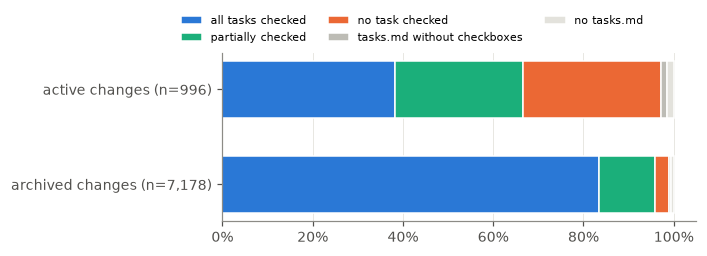

In [8]:
ch['task_status'] = np.select(
    [~ch.has_tasks, ch.n_tasks.fillna(0).eq(0), ch.n_done.eq(ch.n_tasks), ch.n_done.eq(0)],
    ['no tasks.md', 'tasks.md without checkboxes', 'all tasks checked', 'no task checked'], 'partially checked')
ST = ['all tasks checked', 'partially checked', 'no task checked', 'tasks.md without checkboxes', 'no tasks.md']
grp = ch.archived.map({True: 'archived', False: 'active'})
st_tab = pd.crosstab(grp, ch.task_status).reindex(columns=ST, fill_value=0)
st_pct = (100 * st_tab.div(st_tab.sum(axis=1), axis=0)).round(1)
display(save_table(st_tab.join(st_pct, rsuffix=' %'), '07_task_status', index=True))
for lab, d in ch[ch.n_tasks > 0].groupby(grp):
    R[f'any_pending_{lab}'] = cluster_boot(d.assign(p=d.n_pending.gt(0).astype(int)), 'p')
display(pd.DataFrame({k: R[f'any_pending_{k}'] for k in ['active', 'archived']}).T.rename(
    columns={'n': 'changes_with_tasks', 'pct': 'any_pending_pct'}))

fig, ax = plt.subplots(figsize=(6.5, 2.4))
cols = [C['blue'], C['aqua'], C['orange'], '#bdbcb5', '#e3e2dc']
left = np.zeros(2); rows = ['active', 'archived']
for s_, colr in zip(ST, cols):
    v = (st_pct.reindex(rows)[s_] / 100).to_numpy()
    ax.barh(rows, v, left=left, color=colr, label=s_, height=0.6, edgecolor='white', linewidth=1); left += v
ax.set_yticks([0, 1]); ax.set_yticklabels([f'{r} changes (n={st_tab.loc[r].sum():,})' for r in rows])
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.legend(fontsize=7, ncol=3, loc='lower center', bbox_to_anchor=(0.4, 1.0))
savefig(fig, 'F01_task_status')

### 6.3 O que fica pendente

Classificação **heurística por palavras-chave** (`src/openspec_changes.py`), multirrótulo, das linhas desmarcadas (`- [ ]`) de cada `tasks.md`.
É exploratória: orienta a construção de atributos para OM2/OM3 e precisa ser validada à mão.

In [9]:
it = pending_items(osa[osa.kind.eq('tasks.md')])
cat_cols = list(PENDING_CATEGORIES) + [UNCATEGORIZED]
g_it = it.archived.map({True: 'archived', False: 'active'})
cat_tab = (100 * it.groupby(g_it)[cat_cols].mean()).round(1).T
cat_tab.loc['unchecked items (n)'] = it.groupby(g_it).size()
display(save_table(cat_tab, '08_pending_item_categories', index=True))
R['pending_categories'] = cat_tab.to_dict()

archived,active,archived
manual verification / QA,10.0,16.0
automated tests,16.6,22.8
documentation,3.4,5.2
deploy / release / ops,4.2,5.8
optional / follow-up,2.0,4.1
OpenSpec housekeeping,2.4,6.3
uncategorized (likely implementation),68.0,53.7
unchecked items (n),9577.0,9564.0


### 6.4 Protótipo de OM1: estados das mudanças na amostra

,0,1,2
T_days,30.00,60.00,90.00
completed (n),5996.00,5996.00,5996.00
completed with pending tasks (n),1106.00,1106.00,1106.00
archived without task counts (n),76.00,76.00,76.00
in progress (n),277.00,496.00,664.00
overtaken (n),549.00,377.00,252.00
stalled (n),170.00,123.00,80.00
active: in progress %,27.81,49.80,66.67
active: overtaken %,55.12,37.85,25.30
active: stalled %,17.07,12.35,8.03


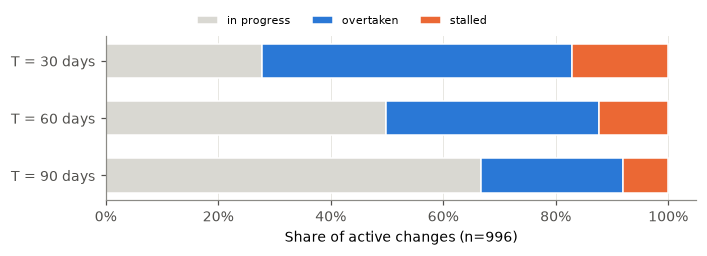

In [10]:
def assign_state(df, T):
    stopped = df.idle_days >= T
    return np.select(
        [df.archived & df.n_pending.eq(0), df.archived & df.n_pending.gt(0), df.archived,
         ~df.archived & ~stopped, ~df.archived & stopped & df.later_archive],
        ['completed', 'completed with pending tasks', 'archived without task counts', 'in progress', 'overtaken'],
        'stalled')

STATES = ['completed', 'completed with pending tasks', 'archived without task counts', 'in progress', 'overtaken', 'stalled']
rows = []
for T in THRESHOLDS:
    s = pd.Series(assign_state(ch, T))
    cnt = s.value_counts().reindex(STATES, fill_value=0)
    row = {'T_days': T, **{f'{k} (n)': int(v) for k, v in cnt.items()}}
    act_s = s[~ch.archived.to_numpy()]
    row['active: in progress %'] = pct(act_s.eq('in progress'))
    row['active: overtaken %'] = pct(act_s.eq('overtaken'))
    row['active: stalled %'] = pct(act_s.eq('stalled'))
    unf = s.isin(['completed with pending tasks', 'overtaken', 'stalled'])
    row['potentially unfinished, all changes %'] = pct(unf)
    rows.append(row)
states = save_table(pd.DataFrame(rows), '09_states_by_threshold'); display(states.T)
R['states'] = states.set_index('T_days').to_dict('index')
ch['state_T30'] = assign_state(ch, 30)

fig, ax = plt.subplots(figsize=(6.5, 2.4))
parts = [('active: in progress %', '#d9d8d2', 'in progress'), ('active: overtaken %', C['blue'], 'overtaken'),
         ('active: stalled %', C['orange'], 'stalled')]
left = np.zeros(len(states)); ylab = [f'T = {t} days' for t in states.T_days]
for col, colr, lab in parts:
    v = (states[col] / 100).to_numpy()
    ax.barh(ylab, v, left=left, color=colr, label=lab, height=0.6, edgecolor='white', linewidth=1); left += v
ax.invert_yaxis(); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_xlabel(f'Share of active changes (n={int((~ch.archived).sum()):,})')
ax.legend(fontsize=7, ncol=3, loc='lower center', bbox_to_anchor=(0.4, 1.0))
savefig(fig, 'F02_active_change_states_by_threshold')

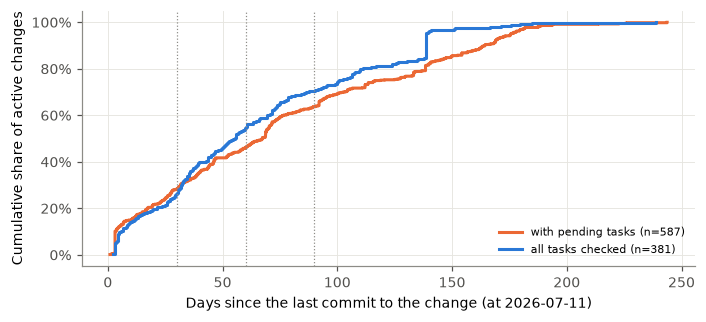

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
for flag, colr, lab in [(True, C['orange'], 'with pending tasks'), (False, C['blue'], 'all tasks checked')]:
    x = np.sort(act.loc[act.n_pending.gt(0).eq(flag) & act.n_tasks.gt(0), 'idle_days'].dropna().to_numpy())
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=colr, label=f'{lab} (n={len(x):,})')
for T in THRESHOLDS: ax.axvline(T, color=C['gray'], lw=0.8, ls=':')
ax.set_xlabel('Days since the last commit to the change (at 2026-07-11)'); ax.set_ylabel('Cumulative share of active changes')
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(fontsize=7.5, loc='lower right')
savefig(fig, 'F03_active_change_idle_days')
R['active_idle_median_days'] = {
    'with_pending': round(float(act.loc[act.n_pending.gt(0), 'idle_days'].median()), 1),
    'all_checked': round(float(act.loc[act.n_pending.eq(0), 'idle_days'].median()), 1)}

In [12]:
# Mudanças ativas paradas (T = 30): tarefas pendentes × tudo marcado mas nunca arquivada
stop = ch[~ch.archived & ch.state_T30.isin(['overtaken', 'stalled']) & ch.n_tasks.gt(0)]
done_flag = stop.n_pending.eq(0).map({True: 'all tasks checked, never archived', False: 'pending tasks'})
xt = pd.crosstab(stop.state_T30, done_flag, margins=True)
display(save_table(xt, '09b_stopped_changes_by_task_completion', index=True))
R['stopped_T30_all_checked'] = cluster_boot(stop.assign(f=stop.n_pending.eq(0).astype(int)), 'f')
print(f"Entre {len(stop)} mudanças ativas paradas (T = 30) com tarefas, {R['stopped_T30_all_checked']['pct']}% "
      f"(IC95% {R['stopped_T30_all_checked']['ci95']}) têm todas as tarefas marcadas e nunca foram arquivadas.")

n_pending,"all tasks checked, never archived",pending tasks,All
state_T30,,,
overtaken,211,330,541
stalled,70,91,161
All,281,421,702


Entre 702 mudanças ativas paradas (T = 30) com tarefas, 40.0% (IC95% [29.8, 50.2]) têm todas as tarefas marcadas e nunca foram arquivadas.


### 6.5 Atributos candidatos para a mineração (OM2 e OM3)

Distribuição dos atributos de conteúdo por estado (T = 30 dias). Atributos de tempo ficam fora, pela assimetria descrita em 4.3.

In [13]:
FEATS = ['n_tasks', 'completion', 'proposal_bytes', 'n_spec_deltas', 'n_code_refs', 'repo_n_changes']
order = ['completed', 'completed with pending tasks', 'in progress', 'overtaken', 'stalled']
desc = ch[ch.state_T30.isin(order)].groupby('state_T30')[FEATS].median().reindex(order).round(2)
desc['has_design %'] = ch.groupby('state_T30').has_design.mean().reindex(order).mul(100).round(1)
desc['changes (n)'] = ch.state_T30.value_counts().reindex(order)
desc['repos (n)'] = ch.groupby('state_T30').repo_name.nunique().reindex(order)
print('Medianas por estado (T = 30 dias):'); display(save_table(desc, '10_features_by_state', index=True))
miss = ch[FEATS + ['has_design']].isna().mean().mul(100).round(1).rename('missing %').to_frame().T
print('Valores ausentes por atributo:'); display(miss)
corr = ch[FEATS].corr(method='spearman').round(2)
print('Correlação de Spearman entre atributos:'); display(save_table(corr, '11_feature_correlation', index=True))

Medianas por estado (T = 30 dias):


,n_tasks,completion,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes,has_design %,changes (n),repos (n)
state_T30,,,,,,,,,
completed,12.0,1.00,2081.0,1.0,1.0,310.0,77.9,5996,125
completed with pending tasks,18.0,0.82,2712.0,1.0,2.0,136.0,77.0,1106,88
in progress,13.0,0.81,3696.0,1.0,2.0,113.0,55.6,277,42
overtaken,19.0,0.87,2377.0,1.0,1.0,100.0,80.1,549,54
stalled,22.0,0.95,2349.0,1.0,2.0,23.0,80.6,170,39


Valores ausentes por atributo:


,n_tasks,completion,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes,has_design
missing %,0.8,1.3,0.1,0.0,0.0,0.0,0.0


Correlação de Spearman entre atributos:


,n_tasks,completion,proposal_bytes,n_spec_deltas,n_code_refs,repo_n_changes
n_tasks,1.00,-0.18,0.62,0.26,0.52,-0.20
completion,-0.18,1.00,-0.15,0.06,-0.08,0.15
proposal_bytes,0.62,-0.15,1.00,0.26,0.49,-0.16
n_spec_deltas,0.26,0.06,0.26,1.00,0.10,0.12
n_code_refs,0.52,-0.08,0.49,0.10,1.00,-0.15
repo_n_changes,-0.20,0.15,-0.16,0.12,-0.15,1.00


## 7. Amostra × censo completo (OpenSpec)

A amostra é curada por estrelas e por PRs, e não representa a população. Comparamos o OpenSpec da amostra com o do censo completo
usando 13 colunas de `spec_files` do censo, baixadas por `scripts/download_data.py` para `data_cache/`. A tabela de artefatos do censo completo entra no
próximo notebook; aqui contamos mudanças a partir dos caminhos dos *spec deltas*.

In [14]:
slim = CACHE / 'full_spec_files_slim.parquet'
if not slim.exists():
    raise FileNotFoundError(f'{slim} não existe: rode `python scripts/download_data.py` antes (ver README)')
full = pd.read_parquet(slim)

def openspec_profile(df):
    d = df[df.spec_tool.eq('openspec') & df.file_total_commits.ge(1)]
    d = d.sort_values('file_url_sha16').drop_duplicates(['repo_name', 'file_path'])
    dirs = d[d.spec_role.isin(['change_proposal', 'archived'])].assign(
        change_dir=lambda x: x.file_path.str.extract(RX_CHANGE)[0]).dropna(subset=['change_dir'])
    cd = dirs[['repo_name', 'change_dir']].drop_duplicates()
    cd_arch = cd.change_dir.str.contains('/changes/archive/')
    repos = d.groupby('repo_name').agg(stars=('repo_stars', 'first'))
    per_repo = cd.groupby('repo_name').size()
    return {
        'OpenSpec specs': len(d), 'OpenSpec repos': len(repos),
        'repos with ≥100 stars %': pct(repos.stars >= 100),
        'living specs %': pct(d.spec_role.eq('living')), 'archived specs %': pct(d.spec_role.eq('archived')),
        'change_proposal specs %': pct(d.spec_role.eq('change_proposal')),
        'change folders (from spec deltas)': len(cd), 'repos with change folders': cd.repo_name.nunique(),
        'archived share of change folders %': pct(cd_arch),
        'change folders per repo, median': float(per_repo.median()),
        'repos that never archived a change %': pct(~cd.assign(a=cd_arch).groupby('repo_name').a.any()),
        'single-commit living specs %': pct(d.loc[d.spec_role.eq('living'), 'file_total_commits'].eq(1)),
    }

cmp = pd.DataFrame({'sample (500 repos)': openspec_profile(sf_raw.assign(commit_history_status='done')),
                    'full broad census': openspec_profile(full[full.commit_history_status.eq('done')])})
display(save_table(cmp.round(2), '12_sample_vs_full_openspec', index=True))
R['sample_vs_full'] = cmp.to_dict()

,sample (500 repos),full broad census
OpenSpec specs,19421.00,259042.00
OpenSpec repos,147.00,8895.00
repos with ≥100 stars %,47.62,1.99
living specs %,23.25,27.00
archived specs %,66.39,56.59
change_proposal specs %,9.41,15.34
change folders (from spec deltas),8364.00,94252.00
repos with change folders,142.00,8429.00
archived share of change folders %,85.81,78.47
"change folders per repo, median",19.00,4.00


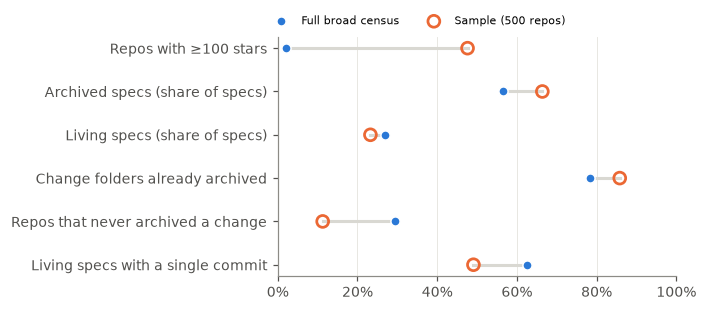

In [15]:
show = [('repos with ≥100 stars %', 'Repos with ≥100 stars'), ('archived specs %', 'Archived specs (share of specs)'),
        ('living specs %', 'Living specs (share of specs)'), ('archived share of change folders %', 'Change folders already archived'),
        ('repos that never archived a change %', 'Repos that never archived a change'),
        ('single-commit living specs %', 'Living specs with a single commit')]
d = cmp.loc[[k for k, _ in show]] / 100
fig, ax = plt.subplots(figsize=(6.5, 2.9)); y = np.arange(len(show))
for yi, (s_, f_) in enumerate(zip(d.iloc[:, 0], d.iloc[:, 1])): ax.plot([s_, f_], [yi, yi], color=C['light'], lw=2, zorder=1)
ax.scatter(d.iloc[:, 1], y, s=36, color=C['blue'], label='Full broad census', zorder=3, edgecolor='white', linewidth=1)
ax.scatter(d.iloc[:, 0], y, s=60, facecolor='none', edgecolor=C['orange'], linewidth=1.8, label='Sample (500 repos)', zorder=4)
ax.set_yticks(y); ax.set_yticklabels([lab for _, lab in show]); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(fontsize=7.5, loc='lower center', bbox_to_anchor=(0.35, 1.0), ncol=2)
savefig(fig, 'F04_sample_vs_full_openspec')

## 8. Síntese e implicações para as próximas etapas

**[Fato] Dados e unidade.** A amostra tem 8.174 mudanças OpenSpec em 142 repositórios (996 ativas, 7.178 arquivadas). A distribuição é concentrada: mediana de 19 mudanças por repositório, máximo de 1.262, e os 5 maiores repositórios somam 41,4% das mudanças.

**[Fato] Sanidade.**

- 2.711 linhas duplicadas entre as specs OpenSpec foram removidas.
- 96,6% das specs arquivadas têm um único commit, e em 86,3% ele está a até 2 dias da data de arquivamento: o histórico anterior ao arquivamento não existe no dataset.
- 100% das mudanças ativas e 99,4% das arquivadas têm *spec delta*. Isso indica que `openspec_artifact_files` foi coletado a partir das pastas descobertas via `spec.md`; 231 pastas vistas em `spec_files` estão ausentes do snapshot (31 repositórios, 116 num único).

**[Fato] Estado das tarefas.** 60,6% das mudanças ativas com tarefas têm itens pendentes (IC95% 51,7–68,8), contra 15,6% das arquivadas (IC95% 11,7–21,1). Nos itens pendentes das arquivadas, testes (22,8%) e verificação manual (16,0%) aparecem mais do que nas ativas (16,6% e 10,0%), mas a maioria dos itens não cai em nenhuma categoria periférica nos dois grupos.

**[Fato] Protótipo de OM1** (T = 30 dias). Das mudanças ativas, 27,8% estão em andamento, 55,1% foram ultrapassadas e 17,1% estão paradas. Somando as arquivadas com pendências, 22,3% de todas as mudanças são potencialmente inacabadas (19,7% com T = 60; 17,6% com T = 90).

**[Fato] Um estado que o modelo não previa.** Entre as 702 mudanças ativas paradas com tarefas, 40,0% (IC95% 29,8–50,2) têm **todas as tarefas marcadas e nunca foram arquivadas**.

**[Fato] Atributos.** Mudanças paradas estão em repositórios menores (mediana de 23 mudanças no repositório, contra 100 a 310 nos outros estados). Mudanças em andamento têm menos `design.md` (55,6%, contra 77% a 81%). Mudanças com pendências têm mais tarefas (mediana de 18 a 22, contra 12 nas concluídas). Os atributos de tamanho são correlacionados entre si (Spearman: tarefas × proposta 0,62; tarefas × referências a código 0,52).

**[Fato] Amostra × censo.** O censo tem 8.895 repositórios OpenSpec e 94.252 pastas de mudança. Comparado à amostra, tem menos mudanças arquivadas (78,5% contra 85,8%), mais repositórios que nunca arquivaram nada (29,4% contra 11,3%), menos mudanças por repositório (mediana 4 contra 19) e muito menos repositórios populares (2,0% contra 47,6% com ≥ 100 estrelas).

**[Interpretação] Implicações para as próximas etapas.**

1. **Refinar os estados (OM1).** Separar as mudanças ativas paradas em "com tarefas pendentes" e "tarefas concluídas, nunca arquivada". O segundo caso é uma falha de fechamento, não de execução, e é justamente o que deixa as specs vivas sem os deltas.
2. **Controlar o tamanho do repositório.** "Ultrapassada" depende de o repositório arquivar outras mudanças, o que é mais provável em repositórios grandes. O tamanho entra como atributo em OM2/OM3, e os intervalos de confiança continuam agrupados por repositório.
3. **Estimar no censo completo.** A amostra superestima o arquivamento e subestima repositórios pequenos. O próximo notebook baixa `openspec_artifact_files` completo (cerca de 420 MB) e reaplica esta construção.
4. **Preparar os atributos para a mineração.** Os atributos de tamanho são redundantes: escolher um representante ou combiná-los antes do agrupamento, e discretizá-los para as regras de associação. Há poucos valores ausentes (até 1,3%).
5. **Declarar a seleção** como ameaça à validade: mudanças sem *spec delta* não estão nos dados, e elas provavelmente são as que param mais cedo.

In [16]:
def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.bool_): return bool(o)
    return o
(OUT / 'key_numbers.json').write_text(json.dumps(to_jsonable(R), indent=2, ensure_ascii=False), encoding='utf-8')
print('Figuras:', sorted(p.name for p in FIG.glob('*.png')))
print('Tabelas:', sorted(p.name for p in TAB.glob('*.csv')))

Figuras: ['F01_task_status.png', 'F02_active_change_states_by_threshold.png', 'F03_active_change_idle_days.png', 'F04_sample_vs_full_openspec.png']
Tabelas: ['01_inventory.csv', '02_artifact_sanity.csv', '03_archive_rename_artifact.csv', '04_change_table_sample.csv', '05_coverage_and_selection.csv', '06_concentration.csv', '07_task_status.csv', '08_pending_item_categories.csv', '09_states_by_threshold.csv', '09b_stopped_changes_by_task_completion.csv', '10_features_by_state.csv', '11_feature_correlation.csv', '12_sample_vs_full_openspec.csv']
